# Simulated next to real data

`iscc` grows a tumor under a regime calibrated on real tumors and fits each assay to real data.
In this tutorial we put its data next to the real data they stand for: a breast tumor measured by single-cell RNA sequencing (scRNA-seq) in the atlas of Wu et al. (2021), and a breast cancer section measured by 10x Visium.
We fit each assay to the real data set with the estimators of `iscc`, measure the [pregrown tumor with immune cells](https://pedrofale.github.io/iscc/reference/#pregrown-tumors) with the fitted settings over the human genes, and compare the two by the cell types, the marker genes, the composition and the depth.

The notebook downloads the atlas (560 MB) and the Visium section once, and runs in about ten minutes on a laptop, with a peak of about 14 GB of memory while the pregrown tumor loads.

In [1]:
import os
import shutil
import tarfile
import urllib.request
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="Variable names are not unique")

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
from scipy.spatial import cKDTree

import iscc.pregrown
from iscc.data import Visium, estimate_rna, estimate_visium, scRNA
from iscc.data.human import HumanGenomeLayer, write_scrna, write_visium
from iscc.integrations import cell_subtypes
from iscc.sample import Resection

sc.settings.verbosity = 0
WORK = sc.settings.datasetdir / "simulated_next_to_real"     # the simulated data sets
WORK.mkdir(parents=True, exist_ok=True)

## A breast tumor in scRNA-seq

Wu et al. (2021) measured 26 primary breast tumors by 10x scRNA-seq, each in its own run, and annotated every cell.
We take tumor CID4066, which holds every cell type of the atlas in good numbers, and map the major cell types of the authors to those of `iscc`: cancer epithelial cells to cancer cells, normal epithelial cells, CAFs to fibroblasts, endothelial cells, perivascular cells (PVL), T cells to T and NK cells, myeloid cells, and B cells and plasmablasts to B and plasma cells.
The atlas is one archive on GEO, and we read the counts of this tumor from it without unpacking the whole matrix.

In [2]:
TUMOR = "CID4066"
WU_TYPES = {"Cancer Epithelial": "cancer", "Normal Epithelial": "epithelial", "CAFs": "fibroblast",
            "Endothelial": "endothelial", "PVL": "PVL", "T-cells": "T_NK", "Myeloid": "myeloid",
            "B-cells": "B_plasma", "Plasmablasts": "B_plasma"}
archive = sc.settings.datasetdir / "GSE176078_Wu_etal_2021_BRCA_scRNASeq.tar.gz"
if not archive.exists():
    url = ("https://ftp.ncbi.nlm.nih.gov/geo/series/GSE176nnn/GSE176078/suppl/"
           "GSE176078_Wu_etal_2021_BRCA_scRNASeq.tar.gz")
    with urllib.request.urlopen(url) as response, open(archive, "wb") as f:
        shutil.copyfileobj(response, f)

with tarfile.open(archive, "r:gz") as tar:
    member = {m.name.split("/")[-1]: m for m in tar.getmembers()}
    barcodes = pd.read_csv(tar.extractfile(member["count_matrix_barcodes.tsv"]), header=None)[0].astype(str)
    genes = pd.read_csv(tar.extractfile(member["count_matrix_genes.tsv"]), header=None)[0].astype(str)
    meta = pd.read_csv(tar.extractfile(member["metadata.csv"]), index_col=0).reindex(barcodes)
    keep = np.flatnonzero(meta["orig.ident"].to_numpy() == TUMOR)
    position = np.full(len(barcodes), -1)
    position[keep] = np.arange(len(keep))
    matrix = tar.extractfile(member["count_matrix_sparse.mtx"])
    while matrix.readline().startswith(b"%"):                # the header ends with the shape line
        pass
    rows, cols, vals = [], [], []
    for chunk in pd.read_csv(matrix, sep=" ", header=None, names=["gene", "cell", "count"], chunksize=20_000_000,
                             dtype={"gene": np.int32, "cell": np.int32, "count": np.float32}):
        at = position[chunk["cell"].to_numpy() - 1]
        rows.append(at[at >= 0])
        cols.append(chunk["gene"].to_numpy()[at >= 0] - 1)
        vals.append(chunk["count"].to_numpy()[at >= 0])
counts = sp.csr_matrix((np.concatenate(vals), (np.concatenate(rows), np.concatenate(cols))),
                       shape=(len(keep), len(genes)))
real = ad.AnnData(counts, obs=meta.iloc[keep].copy(), var=pd.DataFrame(index=genes.to_numpy()))
real.obs["cell_type"] = real.obs["celltype_major"].map(WU_TYPES).to_numpy()
print(f"{TUMOR}: {real.n_obs:,} cells, {real.n_vars:,} genes, a median of "
      f"{np.median(np.asarray(real.X.sum(1)).ravel()):,.0f} UMIs per cell")
real.obs["cell_type"].value_counts().to_dict()

CID4066: 5,309 cells, 29,733 genes, a median of 2,532 UMIs per cell


{'T_NK': 2171,
 'fibroblast': 923,
 'PVL': 630,
 'endothelial': 535,
 'cancer': 521,
 'epithelial': 270,
 'myeloid': 221,
 'B_plasma': 38}

We fit the scRNA assay to this tumor with [`estimate_rna`](https://pedrofale.github.io/iscc/reference/estimate_rna/), which fits the library size and, within groups of similar cells, the dispersion.
We then dissociate the pregrown tumor with immune cells, with the default recovery of each cell type, into about as many cells as the real tumor holds, and measure them with the fitted settings over the human genes of [`HumanGenomeLayer`](https://pedrofale.github.io/iscc/reference/HumanGenomeLayer/).
[`write_scrna`](https://pedrofale.github.io/iscc/reference/write_scrna/) writes the counts as Cell Ranger output, which we read as any 10x data set, and the ground truth gives the cell type of each barcode.
We leave out the doublets, which the authors of the atlas removed from their data.

In [3]:
fit = estimate_rna(real, protocol="10x")
tumor = iscc.pregrown.immune()
specimen = Resection(tumor)
cells = specimen.dissociate(specimen.cancer_region(margin=2), max_cells=real.n_obs, recovery_probs="default", seed=0)
layer = HumanGenomeLayer(tumor)
expression = layer.expression(tumor)
run = scRNA(n_cells=len(cells["cell_exp"]), seed=1, **fit.scrna_kwargs()).run(cells, gene_lift=expression)
write_scrna(WORK / "scrna", run, layer, cells, tumor=tumor)

sim = sc.read_10x_h5(WORK / "scrna" / "outs" / "filtered_feature_bc_matrix.h5")
sim.var_names_make_unique()
truth = pd.read_csv(WORK / "scrna" / "truth" / "cells.tsv", sep="\t", index_col="barcode", dtype={"genotype": str})
sim.obs["cell_type"] = cell_subtypes(truth.loc[sim.obs_names, "genotype"])
sim = sim[~truth.loc[sim.obs_names, "is_doublet"].to_numpy()].copy()
print("fitted:", fit.fitted)
print(f"simulated: {sim.n_obs:,} cells, {sim.n_vars:,} genes, a median of "
      f"{np.median(np.asarray(sim.X.sum(1)).ravel()):,.0f} UMIs per cell")
sim.obs["cell_type"].value_counts().to_dict()

fitted: ['mu_lib', 'sigma_lib', 'dispersion']
simulated: 5,044 cells, 36,601 genes, a median of 3,507 UMIs per cell


{'cancer': 1577,
 'endothelial': 847,
 'T_NK': 760,
 'fibroblast': 749,
 'PVL': 654,
 'myeloid': 236,
 'B_plasma': 146,
 'epithelial': 75}

## The cell types

We run the same scanpy workflow on each data set: normalization, a log transform, 2,000 highly variable genes, 50 principal components, a neighbor graph and a UMAP, and we color the cells by their type in both.

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


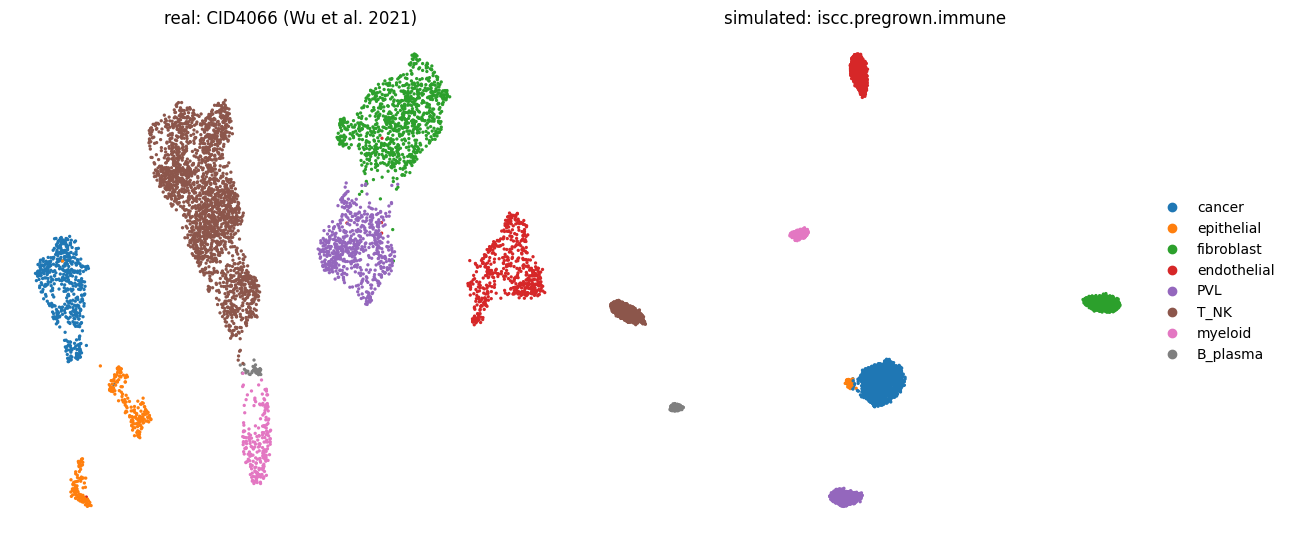

In [4]:
TYPES = ["cancer", "epithelial", "fibroblast", "endothelial", "PVL", "T_NK", "myeloid", "B_plasma"]
PALETTE = dict(zip(TYPES, plt.get_cmap("tab10").colors))

def embed(adata):
    adata.layers["counts"] = adata.X.copy()
    sc.pp.normalize_total(adata, target_sum=1e4)
    sc.pp.log1p(adata)
    sc.pp.highly_variable_genes(adata, n_top_genes=2000)
    sc.pp.pca(adata, n_comps=50, mask_var="highly_variable")
    sc.pp.neighbors(adata)
    sc.tl.umap(adata, random_state=0)
    adata.obs["cell_type"] = pd.Categorical(adata.obs["cell_type"], categories=TYPES)
    return adata

real, sim = embed(real), embed(sim)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, adata, title in [(axes[0], real, f"real: {TUMOR} (Wu et al. 2021)"), (axes[1], sim, "simulated: iscc.pregrown.immune")]:
    sc.pl.umap(adata, color="cell_type", palette=PALETTE, ax=ax, show=False, title=title, frameon=False,
               legend_loc="right margin" if ax is axes[1] else "none")
plt.tight_layout()

The eight cell types form separate clusters in both data sets.
The simulated clusters are tighter than the real ones.
The normal cells of one type in `iscc` share the profile of the type in the Human Breast Cell Atlas and differ only by sampling noise.
The real cells of a type also differ in state: the T and NK cells of CID4066 spread along one long cluster, and its normal epithelial cells form two clusters.
The simulated cancer cells differ by their copy number and their programs, and form one compact cluster.

## Marker genes

For each cell type we show the share of its cells that express each of a few canonical markers and the mean expression of the marker, in both data sets.

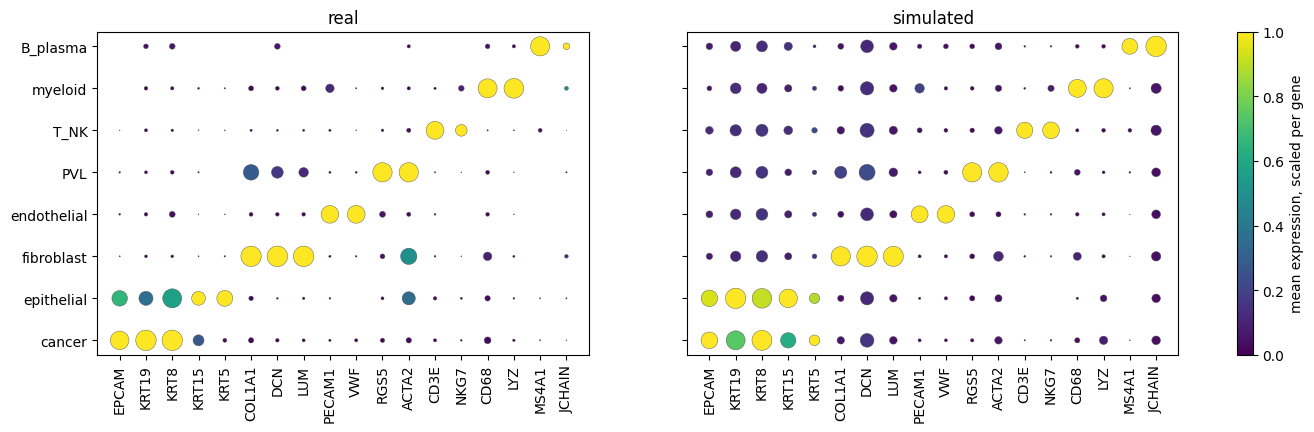

,real,simulated
DCN,0.01,0.47
KRT19,0.02,0.31


In [5]:
MARKERS = {"cancer": ["EPCAM", "KRT19", "KRT8"], "epithelial": ["KRT15", "KRT5"], "fibroblast": ["COL1A1", "DCN", "LUM"],
           "endothelial": ["PECAM1", "VWF"], "PVL": ["RGS5", "ACTA2"], "T_NK": ["CD3E", "NKG7"],
           "myeloid": ["CD68", "LYZ"], "B_plasma": ["MS4A1", "JCHAIN"]}
markers = [g for gs in MARKERS.values() for g in gs]

def marker_table(adata):
    X = adata[:, markers].X
    X = X.toarray() if sp.issparse(X) else np.asarray(X)
    df = pd.DataFrame(X, columns=markers, index=adata.obs_names)
    group = adata.obs["cell_type"]
    return df.groupby(group, observed=True).mean().reindex(TYPES), (df > 0).groupby(group, observed=True).mean().reindex(TYPES)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), sharey=True)
for ax, adata, title in [(axes[0], real, "real"), (axes[1], sim, "simulated")]:
    mean, frac = marker_table(adata)
    scaled = mean / mean.max()                               # each marker scaled to its highest cell type
    yy, xx = np.meshgrid(np.arange(len(TYPES)), np.arange(len(markers)), indexing="ij")
    points = ax.scatter(xx.ravel(), yy.ravel(), s=220 * frac.to_numpy().ravel(), c=scaled.to_numpy().ravel(),
                        cmap="viridis", vmin=0, vmax=1, edgecolor="0.3", linewidth=0.3)
    ax.set(xticks=range(len(markers)), yticks=range(len(TYPES)), title=title)
    ax.set_xticklabels(markers, rotation=90)
    ax.set_yticklabels(TYPES)
    ax.invert_yaxis()
fig.colorbar(points, ax=axes, fraction=0.02, label="mean expression, scaled per gene")
plt.show()

# the share of T and NK cells with at least one UMI of a fibroblast marker (DCN) and of a cancer marker (KRT19)
pd.DataFrame({name: marker_table(adata)[1].loc["T_NK", ["DCN", "KRT19"]] for name, adata in [("real", real), ("simulated", sim)]}).round(2)

The mean expression of each marker is highest in the matching cell type, in both data sets.
The simulated cells contain more RNA of other cell types than the real cells.
Of the simulated T and NK cells, 47% have at least one UMI of the fibroblast marker DCN, against 1% of the real ones, and 31% have a UMI of the cancer marker KRT19, against 2% (table above).
This background has two sources.
The profiles of the atlas are means over the cells of each type, and these cells contain the ambient RNA of the atlas.
The 10x preset then adds an ambient soup of 5% of each library, which `estimate_rna` does not fit.
CID4066 contains little ambient RNA, so the simulated data overstate it for this tumor.

## Composition and depth

The composition of a dissociated sample depends on the tissue that was dissociated and on how well each cell type survives the dissociation.
The depth of a cell is its number of UMIs.

cell_type,cancer,epithelial,fibroblast,endothelial,PVL,T_NK,myeloid,B_plasma
real,0.098,0.051,0.174,0.101,0.119,0.409,0.042,0.007
simulated,0.313,0.015,0.148,0.168,0.130,0.151,0.047,0.029


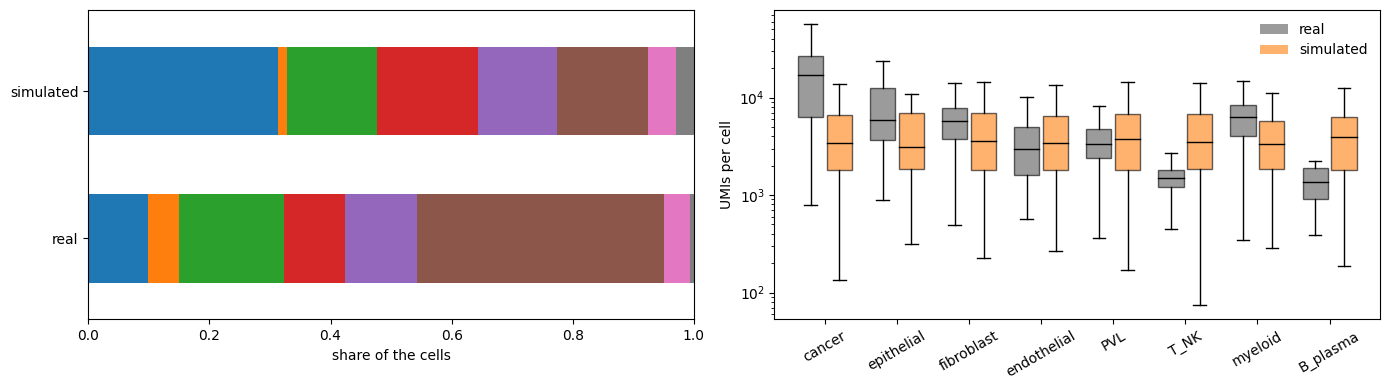

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
share = pd.DataFrame({"real": real.obs["cell_type"].value_counts(normalize=True),
                      "simulated": sim.obs["cell_type"].value_counts(normalize=True)}).reindex(TYPES).fillna(0)
share.T.plot.barh(stacked=True, ax=axes[0], color=[PALETTE[t] for t in TYPES], width=0.6, legend=False)
axes[0].set(xlabel="share of the cells", xlim=(0, 1))
depth = pd.concat([pd.DataFrame({"UMIs": np.asarray(a.layers["counts"].sum(1)).ravel(), "cell type": a.obs["cell_type"].to_numpy(),
                                 "data": name}) for a, name in [(real, "real"), (sim, "simulated")]])
positions = np.arange(len(TYPES))
for offset, (name, colour) in zip((-0.2, 0.2), [("real", "0.35"), ("simulated", "tab:orange")]):
    d = depth[depth["data"] == name]
    axes[1].boxplot([d.loc[d["cell type"] == t, "UMIs"] for t in TYPES], positions=positions + offset, widths=0.35,
                    showfliers=False, patch_artist=True, boxprops=dict(facecolor=colour, alpha=0.6),
                    medianprops=dict(color="black"))
axes[1].set(xticks=positions, yscale="log", ylabel="UMIs per cell")
axes[1].set_xticklabels(TYPES, rotation=30)
axes[1].legend(handles=[plt.Rectangle((0, 0), 1, 1, fc=c, alpha=0.6) for c in ("0.35", "tab:orange")],
               labels=["real", "simulated"], frameon=False)
plt.tight_layout()
share.round(3).T

The simulated sample holds more cancer cells than CID4066 (31% against 10%) and fewer T and NK cells (15% against 41%).
The pregrown tumor is not a model of CID4066, and the share of every cell type in the simulated sample lies within the range of the type over the 26 tumors of the atlas, in which cancer cells make up 0 to 70% of the cells of a tumor and T and NK cells 7 to 84%.

The depth differs the most between the two data sets.
The depth in CID4066 depends on the cell type: the median cancer cell has 17,012 UMIs and the median T or NK cell 1,479.
Every simulated cell type has a median of about 3,500 UMIs, since the library size of a simulated cell is a draw from one log-normal distribution, whatever the type of the cell.
The fitted distribution matches the mean depth of the real cells (5,539 UMIs simulated against 5,318 real) and the spread of the log depth (0.96 against 0.95).
The simulated median (3,507) is higher than the real one (2,532) because the real depths are a mixture of cell types with different depths.

## A breast cancer section in Visium

We fit the Visium assay to the breast cancer section V1_Breast_Cancer_Block_A_Section_1 of 10x Genomics with [`estimate_visium`](https://pedrofale.github.io/iscc/reference/estimate_visium/), as [Shape the data](03_shape_the_data.ipynb) does, cut a thin section of the pregrown tumor in a window of 64 by 64 demes, about 3 mm, around the middle of its cancer cells, and measure it with the fitted settings over the human genes.
We then map the depth of each spot and the expression of a marker of each main cell type in both sections.

In [7]:
sample = "V1_Breast_Cancer_Block_A_Section_1"
sc.datasets.visium_sge(sample)
folder = sc.settings.datasetdir / sample
raw_h5 = folder / "raw_feature_bc_matrix.h5"
if not raw_h5.exists():
    url = f"https://cf.10xgenomics.com/samples/spatial-exp/1.1.0/{sample}/{sample}_raw_feature_bc_matrix.h5"
    request = urllib.request.Request(url, headers={"User-Agent": "scanpy-user"})
    with urllib.request.urlopen(request) as response, open(raw_h5, "wb") as f:
        shutil.copyfileobj(response, f)
real_spots = sc.read_visium(folder, count_file="raw_feature_bc_matrix.h5")
real_spots.var_names_make_unique()
xy = real_spots.obsm["spatial"].astype(float)
pitch = np.median(cKDTree(xy).query(xy, k=2)[0][:, 1])
fit_visium = estimate_visium(real_spots, coords=xy / pitch * 2.0)

center = tuple(int(x) for x in np.mean([tumor.deme_coords[d] for d in specimen.cancer_region(margin=0)], axis=0))
window = tumor.primary_window(side=64, center=center)          # about 3 mm around the middle of the tumor
section = specimen.slice(window, depth_frac=0.5, max_cells=150_000, layers="visium")
visium = Visium(seed=1, section_frac=1.0, **fit_visium.visium_kwargs()).run(section, gene_lift=expression)
write_visium(WORK / "visium", visium, layer, tumor=tumor)
sim_spots = sc.read_10x_h5(WORK / "visium" / "outs" / "filtered_feature_bc_matrix.h5")
sim_spots.var_names_make_unique()
positions = pd.read_csv(WORK / "visium" / "outs" / "spatial" / "tissue_positions.csv", index_col="barcode")
sim_spots.obsm["spatial"] = positions.loc[sim_spots.obs_names, ["pxl_col_in_fullres", "pxl_row_in_fullres"]].to_numpy(float)
real_spots = real_spots[real_spots.obs["in_tissue"] == 1].copy()
for name, adata in [("real", real_spots), ("simulated", sim_spots)]:
    print(f"{name}: {adata.n_obs:,} spots over the tissue, a median of "
          f"{np.median(np.asarray(adata.X.sum(1)).ravel()):,.0f} UMIs per spot")

real: 3,798 spots over the tissue, a median of 20,762 UMIs per spot
simulated: 1,202 spots over the tissue, a median of 17,034 UMIs per spot


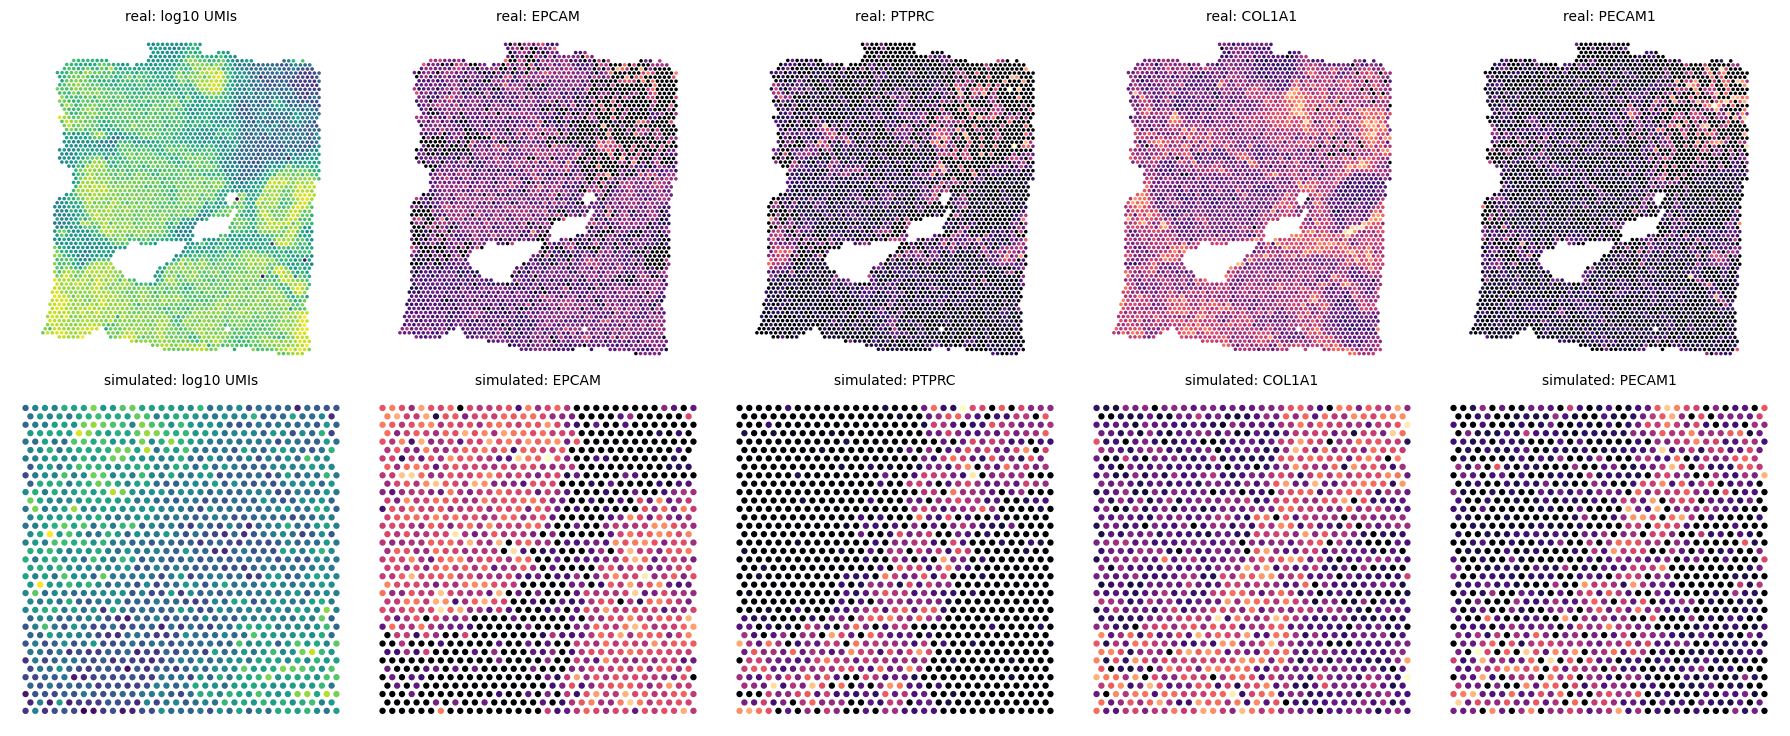

In [8]:
SPOT_MARKERS = ["EPCAM", "PTPRC", "COL1A1", "PECAM1"]

def spot_map(adata, value, ax, title, cmap):
    xy = adata.obsm["spatial"]
    order = np.argsort(value)
    ax.scatter(xy[order, 0], xy[order, 1], c=np.asarray(value)[order], s=25_000 / adata.n_obs,   # the fewer spots, the larger each
               cmap=cmap, linewidth=0)
    ax.set_title(title, fontsize=10)
    ax.set_aspect("equal")
    ax.invert_yaxis()
    ax.axis("off")

fig, axes = plt.subplots(2, 1 + len(SPOT_MARKERS), figsize=(18, 7.5))
for row, (name, adata) in zip(axes, [("real", real_spots), ("simulated", sim_spots)]):
    total = np.asarray(adata.X.sum(1)).ravel()
    spot_map(adata, np.log10(1 + total), row[0], f"{name}: log10 UMIs", "viridis")
    norm = adata.X.multiply(1e4 / total[:, None]).tocsr() if sp.issparse(adata.X) else adata.X * (1e4 / total[:, None])
    for ax, gene in zip(row[1:], SPOT_MARKERS):
        value = np.log1p(np.asarray(norm[:, adata.var_names.get_loc(gene)].todense()).ravel()
                         if sp.issparse(norm) else norm[:, adata.var_names.get_loc(gene)])
        spot_map(adata, value, ax, f"{name}: {gene}", "magma")
plt.tight_layout()

The simulated section is smaller than the real one, 3 mm across against about 6.5 mm, and the markers divide it into regions as they divide the real section.
EPCAM marks the cancer cells in the middle and the upper left of the window, and PTPRC the immune cells outside them, on the right and at the bottom.
COL1A1 and PECAM1 are detected in most spots, without the bands of stroma of the real section, since the stroma of `iscc` has a uniform density.
The depth of the simulated spots shows no pattern of the tissue, while the depth of the real section follows its histology.
The library size of a simulated spot is a log-normal draw times a capture field, whatever cells the spot holds.
The median depths are close: 17,034 UMIs per simulated spot against 20,762 per real spot.

## What matches and what does not

The simulated data hold the cell types of a breast tumor and the canonical markers of each, in a composition within the range of real tumors, at the mean depth and spread of depth fitted to the real data.
Three differences remain, and a benchmark on these data should account for them.

- The normal cells of one type share one profile, so they form tighter clusters than real cells, which also differ in state.
- The simulated cells contain more ambient RNA than CID4066, from the profiles of the atlas and from the ambient soup of the preset.
- The depth of a cell or a spot does not depend on the type or the RNA content of the cells, while a real cancer cell holds many times the UMIs of a real T cell, and the depth of a real section follows its histology.

Unlike real data, the simulated data come with the ground truth: the type, the clone and the copy number of every cell, and the composition of every spot, against which a tool can be scored.